# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

In [1]:
names = "Sae-Jin Moon"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**
Describe how these hyperparameters affect the behavior and output of the algorithms.

a. PCA only does linear projections. It finds straight orthogonal axes that maximize variance across the data, but when points sit along curved manifolds or messy non-linear structures, PCA just flattens them right on top of each other. t-SNE and UMAP do not assume linearity. Instead of projecting onto flat planes, they build graph neighborhoods from pairwise similarities and map those local relationships into 2D, which keeps non-linear structure intact.

b. t-SNE is great at pulling out tight local clusters. But it scales poorly with O(n^2) runtime, so running it on bigger datasets takes forever, and the distances between separate clusters in the final plot do not mean anything real about global distance. UMAP runs much faster because it uses approximate nearest neighbors and scales closer to O(n log n). It also does a much better job keeping global layout so relative positions of clusters still tell you something. We would pick t-SNE for smaller datasets where we only care about local groupings, but we would reach for UMAP on bigger tables or when relative cluster placement matters.

c. For t-SNE, the main knob is `perplexity`, which acts like a smooth measure of how many neighbors each point considers (usually set between 5 and 50). Low perplexity checks only immediate neighbors and tends to tear clusters apart into tiny fragments, while high perplexity pulls in more context and smoothes things out. In UMAP, the main knobs are `n_neighbors` and `min_dist`. `n_neighbors` sets the size of the local metric neighborhood; small counts like 5 track fine local details while larger counts like 50 pull in broad geometry. `min_dist` controls how close points can pack together in 2D, so 0.1 makes tight dense clumps and 0.5 spreads points out across the plot.

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).

Select the following numerical features:

- `bill_length_mm`
- `bill_depth_mm`
- `flipper_length_mm`
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

penguins_url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv"
penguins = pd.read_csv(penguins_url)

feature_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]

penguins_clean = penguins.dropna(subset=feature_cols).copy()
X_penguins = penguins_clean[feature_cols].values
y_penguins = penguins_clean["species"].values

scaler_penguins = StandardScaler()
X_penguins_scaled = scaler_penguins.fit_transform(X_penguins)

print("Penguins dataset shape after dropna:", penguins_clean.shape)
print("Standardized features shape:", X_penguins_scaled.shape)
print("Feature means after scaling (approx 0):", np.round(X_penguins_scaled.mean(axis=0), 4))
print("Feature stds after scaling (approx 1):", np.round(X_penguins_scaled.std(axis=0), 4))

Penguins dataset shape after dropna: (342, 8)
Standardized features shape: (342, 4)
Feature means after scaling (approx 0): [ 0.  0. -0.  0.]
Feature stds after scaling (approx 1): [1. 1. 1. 1.]


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


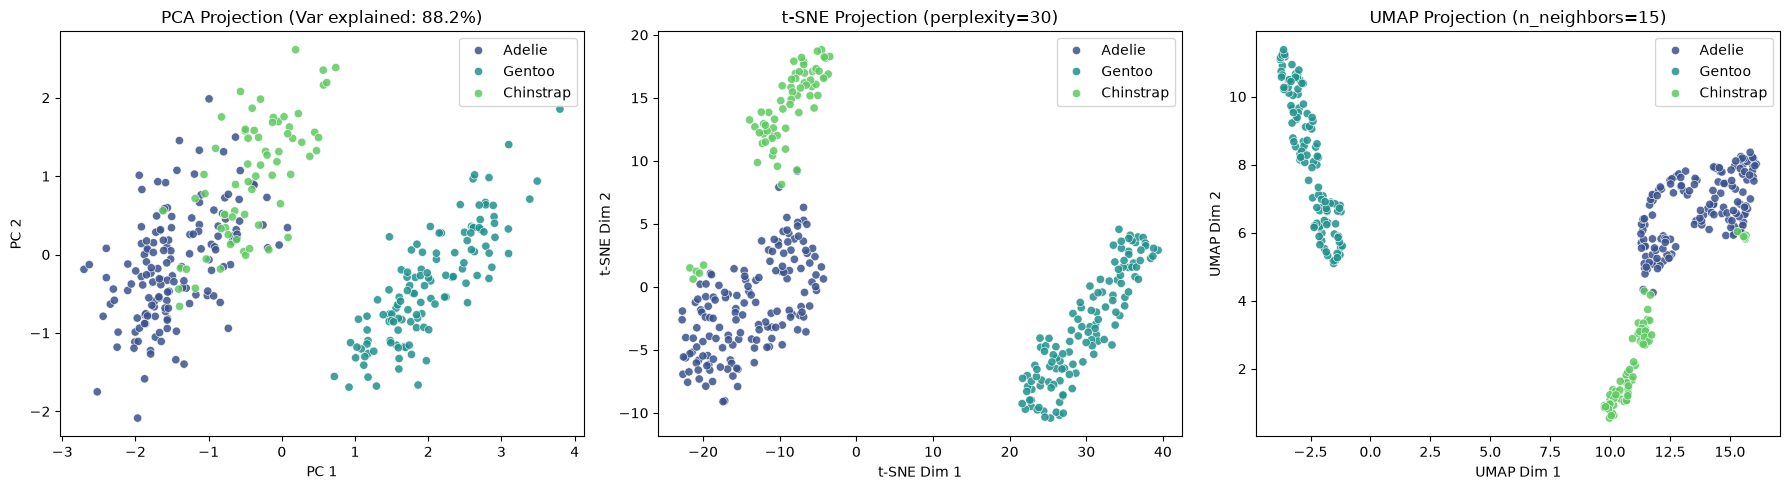

In [6]:
pca_penguins = PCA(n_components=2, random_state=42)
X_pca_penguins = pca_penguins.fit_transform(X_penguins_scaled)

tsne_penguins = TSNE(n_components=2, random_state=42)
X_tsne_penguins = tsne_penguins.fit_transform(X_penguins_scaled)

umap_penguins = umap.UMAP(n_components=2, random_state=42)
X_umap_penguins = umap_penguins.fit_transform(X_penguins_scaled)

fig_pen_2b, axes_pen_2b = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    x=X_pca_penguins[:, 0],
    y=X_pca_penguins[:, 1],
    hue=y_penguins,
    palette="viridis",
    alpha=0.85,
    ax=axes_pen_2b[0],
)
axes_pen_2b[0].set_title(
    f"PCA Projection (Var explained: {sum(pca_penguins.explained_variance_ratio_):.1%})"
)
axes_pen_2b[0].set_xlabel("PC 1")
axes_pen_2b[0].set_ylabel("PC 2")

sns.scatterplot(
    x=X_tsne_penguins[:, 0],
    y=X_tsne_penguins[:, 1],
    hue=y_penguins,
    palette="viridis",
    alpha=0.85,
    ax=axes_pen_2b[1],
)
axes_pen_2b[1].set_title("t-SNE Projection (perplexity=30)")
axes_pen_2b[1].set_xlabel("t-SNE Dim 1")
axes_pen_2b[1].set_ylabel("t-SNE Dim 2")

sns.scatterplot(
    x=X_umap_penguins[:, 0],
    y=X_umap_penguins[:, 1],
    hue=y_penguins,
    palette="viridis",
    alpha=0.85,
    ax=axes_pen_2b[2],
)
axes_pen_2b[2].set_title("UMAP Projection (n_neighbors=15)")
axes_pen_2b[2].set_xlabel("UMAP Dim 1")
axes_pen_2b[2].set_ylabel("UMAP Dim 2")

plt.tight_layout()
plt.show()

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.

Looking at the three 2D plots, `UMAP` isolates all three species cleanest. It throws Gentoo out onto its own island and keeps Adelie and Chinstrap apart with visible white space between them. `TSNE` pulls Gentoo away with no problem too, though Adelie and Chinstrap butt right against each other and blur at the interface. In `PCA`, PC1 captures 68.8% of variance and PC2 captures 19.3% (summing to ~88.2%), yet Adelie and Chinstrap crash right into each other on the left half of the scatter.

Why does that happen? Gentoo penguins are huge compared to the other two, with longer flippers and heavier bodies. Adelie birds match Chinstraps pretty closely on body mass, so their real divergence comes down to bill dimensions (bill length vs bill depth). Because `PCA` only draws linear axes to grab variance, it burns almost all of PC1 on body size, which dumps Adelie and Chinstrap into the exact same region. Non-linear methods like `TSNE` and `UMAP` do not rely on linear projections. They map neighborhood graphs in 4D space where bill differences keep the two species apart, so they pull them into separate 2D clusters. `UMAP` looks cleanest here because its graph layout preserves local groups and keeps the big gap out to Gentoo intact.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


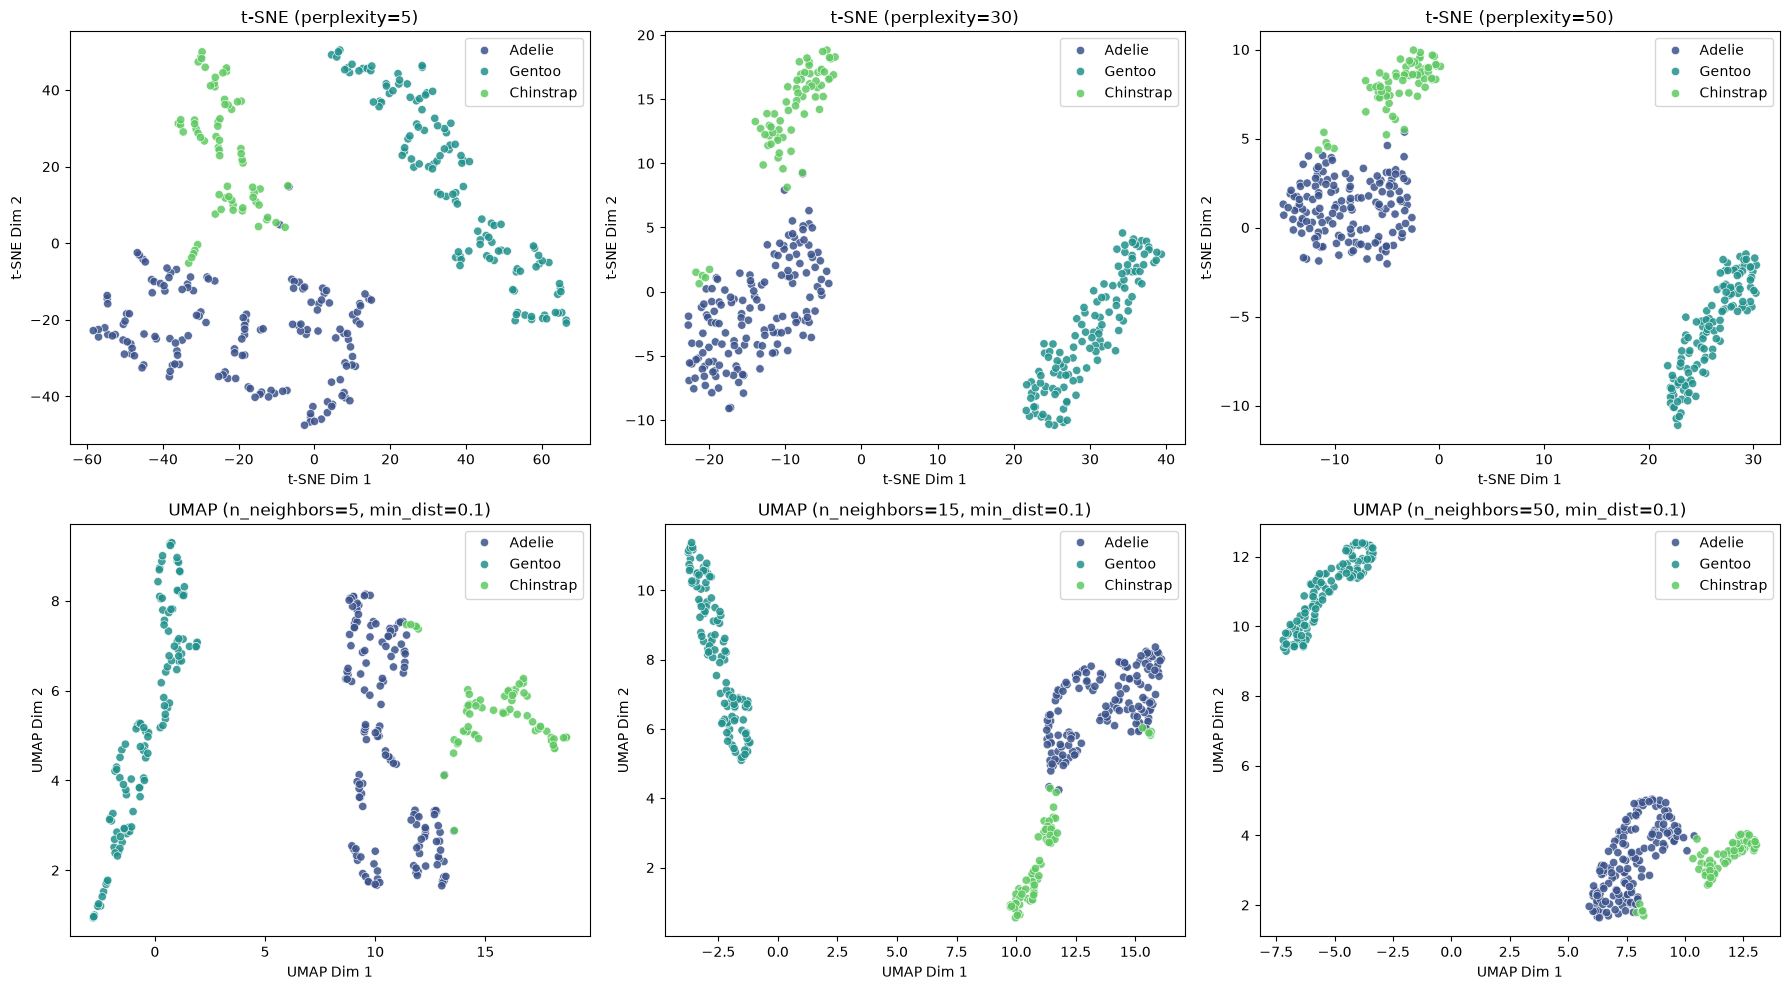

In [4]:
tsne_perplexities = [5, 30, 50]
umap_neighbors = [5, 15, 50]

fig_pen_2d, axes_pen_2d = plt.subplots(2, 3, figsize=(18, 10))

for idx_perp, perp_val in enumerate(tsne_perplexities):
    tsne_param_model = TSNE(n_components=2, perplexity=perp_val, random_state=42)
    X_tsne_sweep = tsne_param_model.fit_transform(X_penguins_scaled)
    sns.scatterplot(
        x=X_tsne_sweep[:, 0],
        y=X_tsne_sweep[:, 1],
        hue=y_penguins,
        palette="viridis",
        alpha=0.85,
        ax=axes_pen_2d[0, idx_perp],
    )
    axes_pen_2d[0, idx_perp].set_title(f"t-SNE (perplexity={perp_val})")
    axes_pen_2d[0, idx_perp].set_xlabel("t-SNE Dim 1")
    axes_pen_2d[0, idx_perp].set_ylabel("t-SNE Dim 2")

for idx_nn, nn_val in enumerate(umap_neighbors):
    umap_param_model = umap.UMAP(n_neighbors=nn_val, min_dist=0.1, random_state=42)
    X_umap_sweep = umap_param_model.fit_transform(X_penguins_scaled)
    sns.scatterplot(
        x=X_umap_sweep[:, 0],
        y=X_umap_sweep[:, 1],
        hue=y_penguins,
        palette="viridis",
        alpha=0.85,
        ax=axes_pen_2d[1, idx_nn],
    )
    axes_pen_2d[1, idx_nn].set_title(f"UMAP (n_neighbors={nn_val}, min_dist=0.1)")
    axes_pen_2d[1, idx_nn].set_xlabel("UMAP Dim 1")
    axes_pen_2d[1, idx_nn].set_ylabel("UMAP Dim 2")

plt.tight_layout()
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

When we sweep `perplexity` from 5 to 50 in `TSNE`, the layout shifts visibly. Setting `perplexity=5` fixates on tiny local pockets, splintering each species into fragmented blobs and blowing out the coordinate scale (reaching from -58 to +66 on dimension 1). Bumping perplexity to 30 pulls points into coherent clusters and tightens the axis range down to [-22, +39]. By 50, everything compresses slightly further. A perplexity around 30 feels like the sweet spot here because it keeps Adelie and Chinstrap apart without tearing either one into fake sub-clusters.

For `UMAP`, tweaking `n_neighbors` from 5 to 50 gradually blends local pockets into unified lobes. With `n_neighbors=5`, the algorithm tears the species into fragmented subgroups. Moving up to 15 (the standard default) yields tight clumps that cleanly separate Gentoo while respecting the boundary between Adelie and Chinstrap. Pushing to 50 expands the neighborhood context and flattens out internal cluster structure even more. Tweaking `min_dist` directly dictates point density: 0.1 jams points into tight pebbles, while 0.5 lets them spread out into looser clouds.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual.

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques.

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

Genotype matrix shape: (3450, 868)
Labels count: 3450 Unique populations: 26


/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


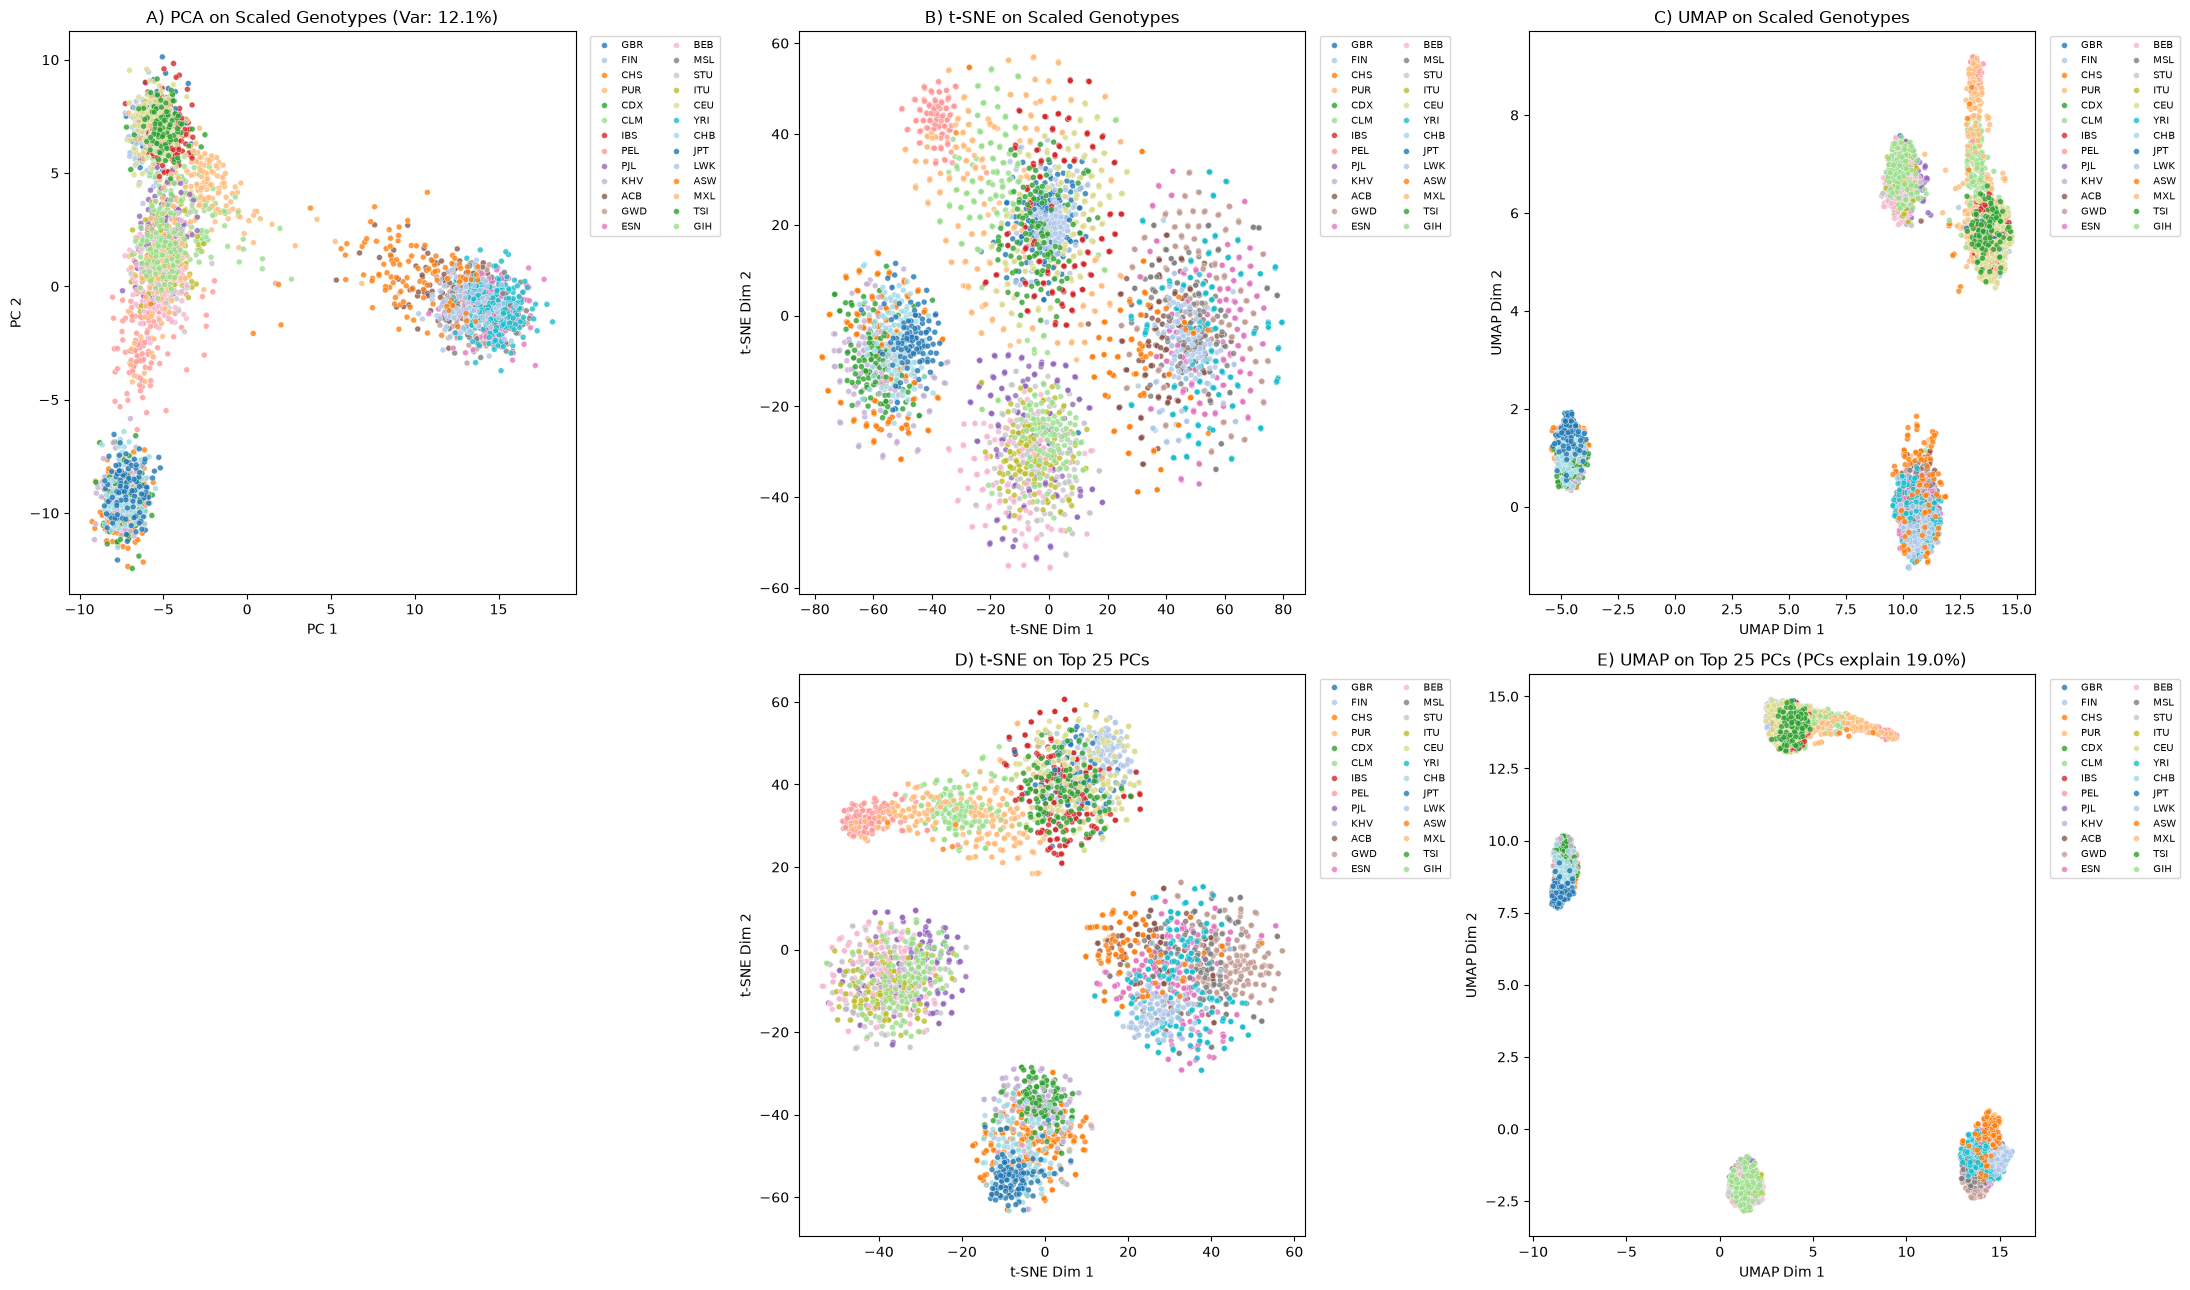

In [5]:
X_genome = np.load("genome_data_lab3.npy")
with open("population_labels_lab3.txt") as f_labels:
    y_genome = np.array([line.strip() for line in f_labels if line.strip()])

X_genome_scaled = StandardScaler().fit_transform(X_genome)

print("Genotype matrix shape:", X_genome.shape)
print("Labels count:", len(y_genome), "Unique populations:", len(np.unique(y_genome)))

pca_gen_2 = PCA(n_components=2, random_state=42)
X_pca_gen_2 = pca_gen_2.fit_transform(X_genome_scaled)

tsne_gen_raw = TSNE(n_components=2, random_state=42)
X_tsne_gen_raw = tsne_gen_raw.fit_transform(X_genome_scaled)

umap_gen_raw = umap.UMAP(random_state=42)
X_umap_gen_raw = umap_gen_raw.fit_transform(X_genome_scaled)

pca_gen_25 = PCA(n_components=25, random_state=42)
X_pca_gen_25 = pca_gen_25.fit_transform(X_genome_scaled)

tsne_gen_pca25 = TSNE(n_components=2, random_state=42)
X_tsne_gen_pca25 = tsne_gen_pca25.fit_transform(X_pca_gen_25)

umap_gen_pca25 = umap.UMAP(random_state=42)
X_umap_gen_pca25 = umap_gen_pca25.fit_transform(X_pca_gen_25)

fig_gen, axes_gen = plt.subplots(2, 3, figsize=(22, 13))

sns.scatterplot(
    x=X_pca_gen_2[:, 0],
    y=X_pca_gen_2[:, 1],
    hue=y_genome,
    palette="tab20",
    s=18,
    alpha=0.8,
    ax=axes_gen[0, 0],
)
axes_gen[0, 0].set_title(
    f"A) PCA on Scaled Genotypes (Var: {sum(pca_gen_2.explained_variance_ratio_):.1%})"
)
axes_gen[0, 0].set_xlabel("PC 1")
axes_gen[0, 0].set_ylabel("PC 2")
axes_gen[0, 0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize="x-small")

sns.scatterplot(
    x=X_tsne_gen_raw[:, 0],
    y=X_tsne_gen_raw[:, 1],
    hue=y_genome,
    palette="tab20",
    s=18,
    alpha=0.8,
    ax=axes_gen[0, 1],
)
axes_gen[0, 1].set_title("B) t-SNE on Scaled Genotypes")
axes_gen[0, 1].set_xlabel("t-SNE Dim 1")
axes_gen[0, 1].set_ylabel("t-SNE Dim 2")
axes_gen[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize="x-small")

sns.scatterplot(
    x=X_umap_gen_raw[:, 0],
    y=X_umap_gen_raw[:, 1],
    hue=y_genome,
    palette="tab20",
    s=18,
    alpha=0.8,
    ax=axes_gen[0, 2],
)
axes_gen[0, 2].set_title("C) UMAP on Scaled Genotypes")
axes_gen[0, 2].set_xlabel("UMAP Dim 1")
axes_gen[0, 2].set_ylabel("UMAP Dim 2")
axes_gen[0, 2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize="x-small")

axes_gen[1, 0].axis("off")

sns.scatterplot(
    x=X_tsne_gen_pca25[:, 0],
    y=X_tsne_gen_pca25[:, 1],
    hue=y_genome,
    palette="tab20",
    s=18,
    alpha=0.8,
    ax=axes_gen[1, 1],
)
axes_gen[1, 1].set_title("D) t-SNE on Top 25 PCs")
axes_gen[1, 1].set_xlabel("t-SNE Dim 1")
axes_gen[1, 1].set_ylabel("t-SNE Dim 2")
axes_gen[1, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize="x-small")

sns.scatterplot(
    x=X_umap_gen_pca25[:, 0],
    y=X_umap_gen_pca25[:, 1],
    hue=y_genome,
    palette="tab20",
    s=18,
    alpha=0.8,
    ax=axes_gen[1, 2],
)
axes_gen[1, 2].set_title(
    f"E) UMAP on Top 25 PCs (PCs explain {sum(pca_gen_25.explained_variance_ratio_):.1%})"
)
axes_gen[1, 2].set_xlabel("UMAP Dim 1")
axes_gen[1, 2].set_ylabel("UMAP Dim 2")
axes_gen[1, 2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize="x-small")

plt.tight_layout()
plt.show()

Looking at the 2D projections of the 3450 samples across 26 populations, `PCA` arranges people into a broad triangle where the vertices mark African, East Asian, and European ancestries. PC1 and PC2 only account for 8.9% and 3.2% of variance (about 12.1% combined). Because 88% of genetic variance gets discarded in 2D, groups with separate origins such as South Asians (GIH, PJL) and admixed American samples (CLM, MXL) end up smearing together in the interior of the triangle.

`TSNE` groups people roughly by continental origin, though it suffers from convergence problems: many points form scattered peripheral clouds instead of tight clumps, and European samples like GBR and CEU remain blurry with Hispanic populations. `UMAP` provides the cleanest separation of populations into fine-grained sub-clusters. It resolves East Asian groups (CHB/CHS vs CDX/KHV), isolates separated populations like Finnish (FIN) and Luhya (LWK), and keeps continental groups organized. This matches what Diaz-Papkovich et al. (2019) report in Figure 1: UMAP models topology better and preserves both local sub-population boundaries and continental structure.

Preprocessing with the top 25 principal components before applying `TSNE` or `UMAP` creates much tighter clusters. Reducing from 868 genetic variants down to 25 PCs filters out uncorrelated SNP noise while keeping approximately 19.0% of the total variance. As Diaz-Papkovich et al. point out, running UMAP on top PCs speeds up distance calculations and removes high-dimensional noise, which turns fuzzy continental clouds into sharply resolved sub-population clusters.

On trade-offs between interpretability and performance: `PCA` is linear, runs fastest (under 0.1s), and has interpretable axes corresponding to orthogonal variance directions. But its 2D visual separation on real genomic data is poor because non-linear admixture cannot fit onto two linear planes. `TSNE` isolates local groups well when tuned, but distances between clusters are arbitrary and runtime scales quadratically (taking ~16.6s raw vs ~11.0s on 25 PCs). `UMAP` hits the best practical compromise. It runs in ~8.6s raw and ~7.0s on 25 PCs, separates fine-scale populations, and preserves enough global geometry that relative cluster positions remain biologically meaningful.

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Early on, our group ran into an annoying coordination problem: we tested different UMAP and t-SNE parameters across our machines without pinning down random seeds first, so scatter plots drifted between runs and nobody could tell if a cluster moved due to hyperparameter tweaks or just random jitter. Classic debugging headache. For the next lab, we decided to lock down a shared setup cell at the very top of the notebook that hardcodes `random_state=42` and plotting defaults before anyone starts running experiments.